# ECG Classification: CNN vs ResNet1D

In this notebook, we implement and compare two deep learning architectures for multi-label ECG classification using the PTB-XL dataset.

We focus on: CNN (baseline), ResNet1D (deep architecture)

The task is formulated as a multi-label classification problem over selected diagnostic superclasses.

In [11]:
import sys
from pathlib import Path


PROJECT_ROOT = Path(r"C:\Users\Sherif\Desktop\ECG analysis")

sys.path.insert(0, str(PROJECT_ROOT))

In [18]:
import importlib
import src.train

importlib.reload(src.train)

import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt

from tqdm import tqdm
from sklearn.metrics import classification_report, roc_auc_score

from models.cnn1D import CNN1D
from models.resnet1D import ResNet1D
from src.dataset import create_dataloaders
from src.train import train_model, test_model

In [3]:
import random
import numpy as np
import torch

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

    # pour reproductibilité (important)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)

In [4]:
generator = torch.Generator()
generator.manual_seed(42)

In [5]:
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

BATCH_SIZE = 64
EPOCHS = 50
LR = 1e-4

# i'm adding this because i want to try with 3 superclasses (the most balanced betwenn them)
SELECTED_CLASSES = ["MI", "STTC", "CD"]

In [6]:
train_loader, val_loader, test_loader, label_cols, class_weights = create_dataloaders(
    batch_size=BATCH_SIZE
)
num_classes = len(label_cols)
print("Classes:", label_cols)

Classes: ['CD', 'HYP', 'MI', 'NORM', 'STTC']


In [7]:
cnn_model = CNN1D(num_classes)
resnet_model = ResNet1D(layers=[2,2,2,2], num_classes=num_classes)

#### CNN training 

In [8]:
cnn_model, cnn_history = train_model(
    cnn_model,
    train_loader,
    val_loader,
    class_weights,   # 🔥 IMPORTANT
    epochs=50,
    lr=1e-4,
    device=DEVICE
)


Epoch 1/50


Evaluating: 100%|██████████| 35/35 [00:25<00:00,  1.35it/s]


Train Loss: 0.9909
Val Loss:   0.8889
Val AUC:    0.7555
Best model saved

Epoch 2/50


Evaluating: 100%|██████████| 35/35 [00:27<00:00,  1.29it/s]


Train Loss: 0.8621
Val Loss:   0.8389
Val AUC:    0.7813
Best model saved

Epoch 3/50


Evaluating: 100%|██████████| 35/35 [00:27<00:00,  1.29it/s]


... (91 outputs left out)

Evaluating: 100%|██████████| 35/35 [00:28<00:00,  1.24it/s]


Train Loss: 0.5988
Val Loss:   0.6400
Val AUC:    0.8818
Best model saved

Epoch 50/50


Evaluating: 100%|██████████| 35/35 [00:30<00:00,  1.15it/s]

Train Loss: 0.5980
Val Loss:   0.6445
Val AUC:    0.8823
Best model saved


In [20]:
y_true_cnn, y_pred_cnn, cnn_auc = test_model(
    cnn_model,
    test_loader,
    label_cols,   
    DEVICE        # ✅
)

Testing: 100%|██████████| 35/35 [00:26<00:00,  1.33it/s]


Test Macro AUC: 0.8799

Classification Report:
              precision    recall  f1-score   support

          CD       0.61      0.78      0.68       496
         HYP       0.25      0.74      0.37       262
          MI       0.51      0.85      0.64       550
        NORM       0.81      0.82      0.81       963
        STTC       0.53      0.92      0.67       521

   micro avg       0.55      0.83      0.66      2792
   macro avg       0.54      0.82      0.64      2792
weighted avg       0.61      0.83      0.69      2792
 samples avg       0.62      0.81      0.67      2792


F1 (macro): 0.635224319405757
Precision (macro): 0.5399777544970402
Recall (macro): 0.8207829936746529



c:\Users\Sherif\Desktop\ECG analysis\venv\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in samples with no predicted labels. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\Sherif\Desktop\ECG analysis\venv\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in samples with no true labels. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


#### Resnet1D training 

In [21]:
resnet_model, resnet_history = train_model(
    resnet_model,
    train_loader,
    val_loader,
    class_weights,
    epochs=50,
    lr=1e-4,
    device=DEVICE
)


Epoch 1/50


Evaluating: 100%|██████████| 35/35 [00:32<00:00,  1.06it/s]


Train Loss: 0.6857
Val Loss:   0.7242
Val AUC:    0.8697
Best model saved

Epoch 2/50


Evaluating: 100%|██████████| 35/35 [00:36<00:00,  1.04s/it]


Train Loss: 0.5745
Val Loss:   0.7043
Val AUC:    0.8838
Best model saved

Epoch 3/50


Evaluating: 100%|██████████| 35/35 [00:43<00:00,  1.24s/it]


... (91 outputs left out)

Evaluating: 100%|██████████| 35/35 [00:32<00:00,  1.08it/s]


Train Loss: 0.0847
Val Loss:   1.7892
Val AUC:    0.8527

Epoch 50/50


Evaluating: 100%|██████████| 35/35 [00:32<00:00,  1.08it/s]

Train Loss: 0.0203
Val Loss:   1.9093
Val AUC:    0.8668


In [22]:
y_true_resnet, y_pred_resnet, resnet_auc = test_model(resnet_model, test_loader, label_cols, DEVICE)

Testing: 100%|██████████| 35/35 [00:43<00:00,  1.23s/it]


Test Macro AUC: 0.8726

Classification Report:
              precision    recall  f1-score   support

          CD       0.67      0.68      0.68       496
         HYP       0.43      0.36      0.39       262
          MI       0.70      0.60      0.65       550
        NORM       0.78      0.87      0.82       963
        STTC       0.67      0.72      0.70       521

   micro avg       0.70      0.71      0.70      2792
   macro avg       0.65      0.65      0.65      2792
weighted avg       0.69      0.71      0.70      2792
 samples avg       0.69      0.71      0.69      2792


F1 (macro): 0.6456572645458013
Precision (macro): 0.6490528818372733
Recall (macro): 0.6461436623009073



c:\Users\Sherif\Desktop\ECG analysis\venv\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in samples with no predicted labels. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\Sherif\Desktop\ECG analysis\venv\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in samples with no true labels. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\Sherif\Desktop\ECG analysis\venv\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in samples with no true nor predicted labels. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()}

In [24]:
import pandas as pd
results_df = pd.DataFrame({
    "Model": ["CNN1D", "ResNet1D"],
    "Macro AUC": [cnn_auc, resnet_auc],
})

results_df

,Model,Macro AUC
0,CNN1D,0.879893
1,ResNet1D,0.872584


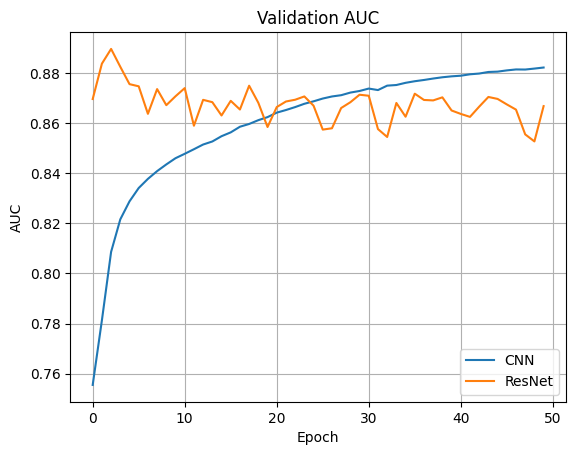

In [25]:
import matplotlib.pyplot as plt

plt.plot(cnn_history["val_auc"], label="CNN")
plt.plot(resnet_history["val_auc"], label="ResNet")

plt.title("Validation AUC")
plt.xlabel("Epoch")
plt.ylabel("AUC")
plt.legend()
plt.grid()
plt.show()